# Does Singapore gasoil represent MGO?

**Jira:** MPP-48 · *As a buyer, I want evidence the Gasoil proxy represents MGO*

Our forecasting work leans on Singapore gasoil futures as a stand-in (proxy) for the Singapore MGO bunker price,
because gasoil trades every day while we only have 253 irregular MGO quotes. This notebook checks whether that is
justified. It:

1. confirms the quoting units and defines the barrel → tonne conversion,
2. builds a matched-date dataset of gasoil and MGO,
3. measures how closely they move together (correlation, slope, plots),
4. defines the basis conversion rule and when to apply it with care, and
5. produces a chart and short text for the Model Trust page.

All data comes from the shared snapshot `models/ridge-regression/data/raw/market_observations.csv`.
Nothing is forecast here: every comparison uses **observed** gasoil and MGO prices.

In [1]:
from pathlib import Path
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

# Find the repo root from wherever the notebook is opened.
REPO = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "models").is_dir())
DATA = REPO / "models/ridge-regression/data"
OUT = REPO / "analysis/gasoil-mgo-proxy"

GASOIL, MGO = "sg_gasoil_investing", "sg_mgo_themaritime"
market = pd.read_csv(DATA / "raw/market_observations.csv", parse_dates=["date"])

def load(series):
    s = market.loc[market.series == series, ["date", "value"]].dropna()
    return s.set_index("date")["value"].sort_index()

gasoil, mgo = load(GASOIL), load(MGO)
print(f"Gasoil: {len(gasoil):,} daily closes, {gasoil.index.min().date()} to {gasoil.index.max().date()}")
print(f"MGO:    {len(mgo):,} quotes,       {mgo.index.min().date()} to {mgo.index.max().date()}")

Gasoil: 2,510 daily closes, 2016-10-06 to 2026-10-05
MGO:    253 quotes,       2020-03-13 to 2026-10-06


## 1. Units and the barrel → tonne conversion

The series dictionary records each series' quoting unit:

In [2]:
dictionary = pd.read_csv(DATA / "metadata/series_dictionary.csv")
cols = [c for c in dictionary.columns if c in ("series", "label", "unit", "currency", "frequency", "price_basis")]
dictionary.loc[dictionary.series.isin([GASOIL, MGO]), cols]

,series,label,unit,currency,frequency
2,sg_gasoil_investing,Singapore gasoil futures,USD/barrel,USD,daily trading-date observations
4,sg_mgo_themaritime,Singapore MGO bunker indication,USD/metric tonne,USD,irregular observed quote dates; underlying pro...


**Gasoil is quoted in USD per barrel (a volume); MGO is quoted in USD per metric tonne (a weight).**
To compare price *levels* we need barrels per tonne, which depends on the fuel's density:

$$\text{barrels per tonne} = \frac{1000\ \text{kg}}{\text{density (kg/L)} \times 158.987\ \text{L/barrel}}$$

The project's data dictionary warns that a generic factor is not enough; the conversion should be product-specific.
We use **7.45 barrels/tonne**, the conventional conversion factor for Singapore gasoil in industry price reporting.
It corresponds to a density of about **0.844 kg/L**, which is typical for gasoil/diesel and within the
ISO 8217 limit for distillate marine fuel (DMA, at most 0.890 kg/L at 15 °C).

> **Source for 7.45:** ICE Futures uses 1 metric tonne = 7.45 barrels to convert the Platts Singapore gasoil price
> to tonnes ([contract specification](https://www.ice.com/products/65898861/Gasoil-Arb---Singapore-Gasoil-(Platts)-vs-Low-Sulphur-Gasoil-1st-Line-Balmo-Future-(in-Bbls))). This converts gasoil only; MGO is already quoted per tonne.

Notes on the conversion:
- 7.45 comes from the exchange convention above, **not from our dataset**. The MGO quote's exact grade (sulphur, ISO class) is
  not recorded, so its true density is unknown.
- **Percentage changes don't need any conversion.** A 2% gasoil move is 2% per barrel or per tonne. Only the
  dollar *level* comparison (the basis, section 4) depends on this factor, so we show how sensitive it is below.

In [3]:
LITRES_PER_BARREL = 158.987
BBL_PER_TONNE = 7.45

print(f"Implied density at {BBL_PER_TONNE} bbl/t: {1000 / (BBL_PER_TONNE * LITRES_PER_BARREL):.3f} kg/L")

sensitivity = pd.DataFrame({"bbl_per_tonne": [7.20, 7.30, 7.45, 7.60, 7.70]})
sensitivity["implied_density_kg_per_L"] = 1000 / (sensitivity.bbl_per_tonne * LITRES_PER_BARREL)
sensitivity.round(3)

Implied density at 7.45 bbl/t: 0.844 kg/L


,bbl_per_tonne,implied_density_kg_per_L
0,7.20,0.874
1,7.30,0.862
2,7.45,0.844
3,7.60,0.828
4,7.70,0.817


## 2. Matched-date dataset

**Matching rule:** each MGO quote is paired with the **most recent gasoil close on or before the MGO quote date**
(same day allowed, at most 7 calendar days old). MGO quotes are never interpolated or invented.
Same-day pairing is fine here because we are measuring the relationship, not making a forecast.

In [4]:
matched = pd.merge_asof(
    mgo.rename("mgo_usd_per_t").rename_axis("mgo_date").reset_index(),
    gasoil.rename("gasoil_usd_per_bbl").rename_axis("gasoil_date").reset_index(),
    left_on="mgo_date", right_on="gasoil_date", direction="backward",
    tolerance=pd.Timedelta(days=7),
)
matched["gasoil_age_days"] = (matched.mgo_date - matched.gasoil_date).dt.days
matched["gasoil_usd_per_t"] = matched.gasoil_usd_per_bbl * BBL_PER_TONNE
matched["basis_usd_per_t"] = matched.mgo_usd_per_t - matched.gasoil_usd_per_t

print(f"{matched.gasoil_date.notna().sum()} of {len(matched)} MGO quotes matched")
print("Gasoil age (days):", matched.gasoil_age_days.value_counts().sort_index().to_dict())
matched.round(2).to_csv(OUT / "matched_dates.csv", index=False)
print("Saved", (OUT / "matched_dates.csv").relative_to(REPO))
matched.round(2).tail()

253 of 253 MGO quotes matched
Gasoil age (days): {0: 175, 1: 41, 2: 32, 3: 5}
Saved analysis/gasoil-mgo-proxy/matched_dates.csv


,mgo_date,mgo_usd_per_t,gasoil_date,gasoil_usd_per_bbl,gasoil_age_days,gasoil_usd_per_t,basis_usd_per_t
248,2026-10-02,1297.0,2026-10-02,166.52,0,1240.57,56.43
249,2026-10-03,1297.0,2026-10-02,166.52,1,1240.57,56.43
250,2026-10-04,1297.0,2026-10-02,166.52,2,1240.57,56.43
251,2026-10-05,1297.0,2026-10-05,168.48,0,1255.18,41.82
252,2026-10-06,1278.5,2026-10-05,168.48,1,1255.18,23.32


## 3. How closely do they move together?

### 3a. Prices over time

Gasoil converted to USD/tonne, on the same axis as MGO, with the gap between them (the basis) underneath.

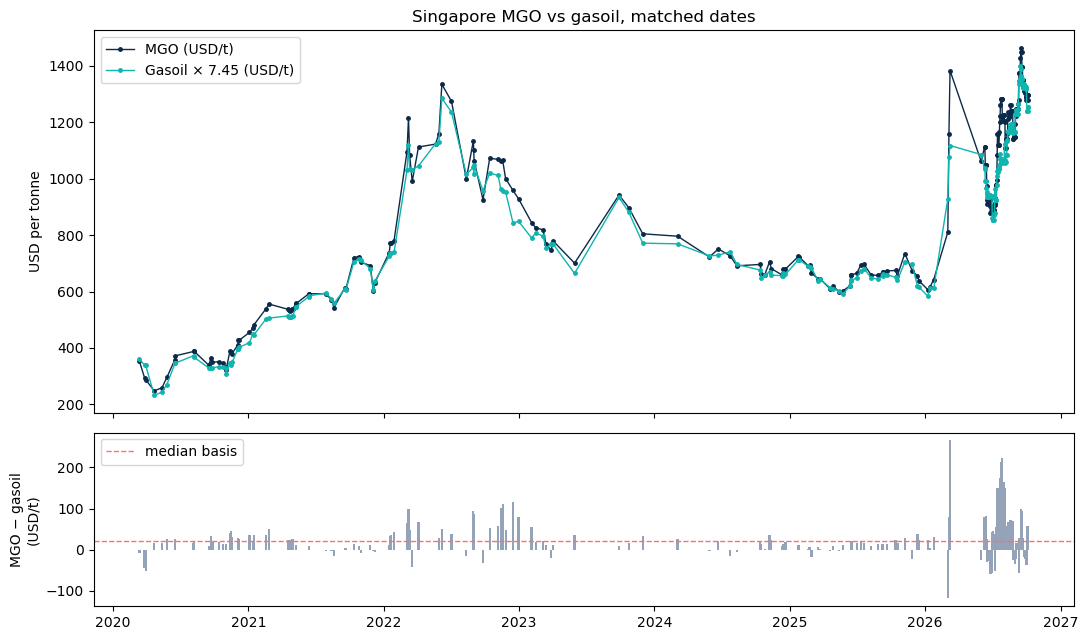

Correlation of price levels: 0.986


In [5]:
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(11, 6.5), sharex=True, gridspec_kw={"height_ratios": [2.2, 1]})
ax1.plot(matched.mgo_date, matched.mgo_usd_per_t, "o-", ms=2.5, lw=1, color="#0B2A4A", label="MGO (USD/t)")
ax1.plot(matched.mgo_date, matched.gasoil_usd_per_t, "o-", ms=2.5, lw=1, color="#0FB5AE",
         label=f"Gasoil × {BBL_PER_TONNE} (USD/t)")
ax1.set_ylabel("USD per tonne"); ax1.legend(); ax1.set_title("Singapore MGO vs gasoil, matched dates")
ax2.bar(matched.mgo_date, matched.basis_usd_per_t, width=6, color="#94A3B8")
ax2.axhline(matched.basis_usd_per_t.median(), color="#F87171", lw=1, ls="--", label="median basis")
ax2.set_ylabel("MGO − gasoil\n(USD/t)"); ax2.legend()
fig.tight_layout(); plt.show()

level_r = matched[["mgo_usd_per_t", "gasoil_usd_per_t"]].corr().iloc[0, 1]
print(f"Correlation of price levels: {level_r:.3f}")

The price levels track each other closely, but a high correlation of **levels** is weak evidence on its own: any two
prices that both trend up and down over years will look correlated. The stronger test is whether their **changes**
line up, which is next.

### 3b. Returns: does MGO move when gasoil moves?

For each pair of consecutive MGO quotes we compare MGO's % change with gasoil's % change over the **same dates**.
The slope answers "how much does MGO move per 1% gasoil move?". A slope of 1 means equal percentage moves, the
simplest way to carry a gasoil move over to MGO.

Most 2026 quotes are one day apart, but earlier ones can be weeks apart, so we report all intervals and short
(≤ 7 day) intervals separately.

In [6]:
pairs = matched.assign(
    days=matched.mgo_date.diff().dt.days,
    mgo_return=matched.mgo_usd_per_t.pct_change(),
    gasoil_return=matched.gasoil_usd_per_bbl.pct_change(),
    mgo_prev=matched.mgo_usd_per_t.shift(),
    gasoil_t_prev=matched.gasoil_usd_per_t.shift(),
    basis_prev=matched.basis_usd_per_t.shift(),
).dropna(subset=["mgo_return", "gasoil_return"])

# The March 2026 shock: MGO +70% in six days while gasoil rose ~20% (see section 4).
SHOCK = pairs.mgo_date.between("2026-03-03", "2026-03-12")

def relationship(df, label):
    fit = stats.linregress(df.gasoil_return, df.mgo_return)
    t = stats.t.ppf(0.975, len(df) - 2)
    return {"sample": label, "pairs": len(df),
            "pearson_r": fit.rvalue, "spearman_r": stats.spearmanr(df.gasoil_return, df.mgo_return)[0],
            "slope": fit.slope, "slope_95ci_low": fit.slope - t * fit.stderr,
            "slope_95ci_high": fit.slope + t * fit.stderr, "intercept_pct": 100 * fit.intercept}

short = pairs.days <= 7
results = pd.DataFrame([
    relationship(pairs, "all intervals"),
    relationship(pairs[short], "≤ 7 days"),
    relationship(pairs[~SHOCK], "all, excl. Mar-2026 shock"),
    relationship(pairs[short & ~SHOCK], "≤ 7 days, excl. Mar-2026 shock"),
]).set_index("sample")
results.round(3)

,pairs,pearson_r,spearman_r,slope,slope_95ci_low,slope_95ci_high,intercept_pct
sample,,,,,,,
all intervals,252,0.799,0.638,0.827,0.749,0.904,0.160
≤ 7 days,169,0.591,0.415,1.059,0.838,1.280,0.171
"all, excl. Mar-2026 shock",249,0.825,0.625,0.866,0.792,0.941,0.028
"≤ 7 days, excl. Mar-2026 shock",167,0.402,0.394,0.513,0.334,0.693,-0.023


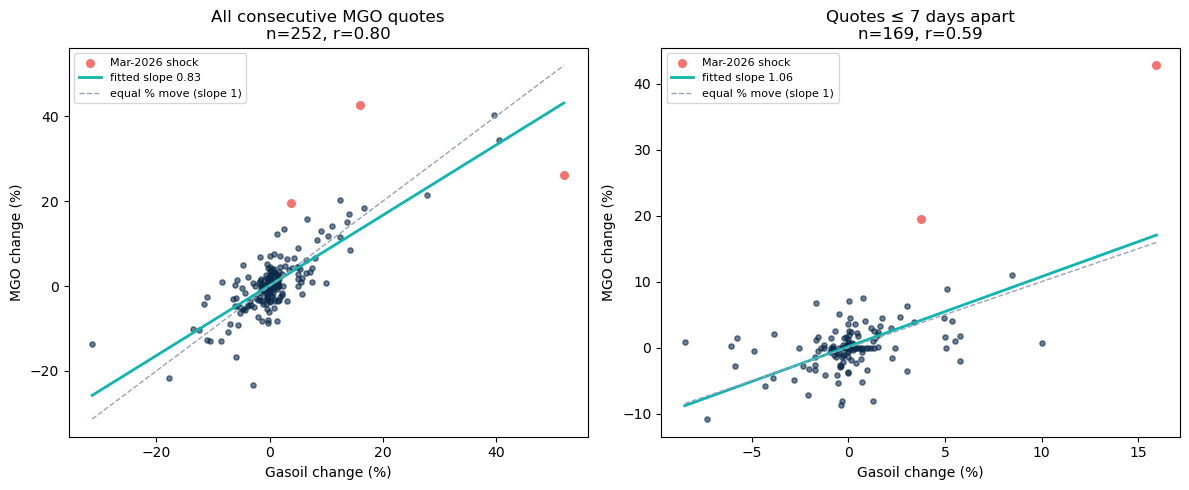

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
for ax, (df, title) in zip(axes, [(pairs, "All consecutive MGO quotes"), (pairs[short], "Quotes ≤ 7 days apart")]):
    fit = stats.linregress(df.gasoil_return, df.mgo_return)
    ax.scatter(100 * df.gasoil_return, 100 * df.mgo_return, s=14, alpha=0.6, color="#0B2A4A")
    ax.scatter(100 * df.gasoil_return[SHOCK], 100 * df.mgo_return[SHOCK], s=30, color="#F87171",
               label="Mar-2026 shock")
    x = np.linspace(100 * df.gasoil_return.min(), 100 * df.gasoil_return.max(), 50)
    ax.plot(x, fit.intercept * 100 + fit.slope * x, color="#0FB5AE", lw=2, label=f"fitted slope {fit.slope:.2f}")
    ax.plot(x, x, color="#94A3B8", lw=1, ls="--", label="equal % move (slope 1)")
    ax.set_xlabel("Gasoil change (%)"); ax.set_ylabel("MGO change (%)")
    ax.set_title(f"{title}\nn={len(df)}, r={fit.rvalue:.2f}"); ax.legend(fontsize=8)
fig.tight_layout(); plt.show()

### 3c. Is the relationship stable over time?

In [8]:
periods = {"2020–2021": ("2020", "2021"), "2022": ("2022", "2022"),
           "2023–2025": ("2023", "2025"), "2026": ("2026", "2026")}
by_period = pd.DataFrame([
    relationship(pairs[pairs.mgo_date.dt.year.between(int(a), int(b))], name) for name, (a, b) in periods.items()
]).set_index("sample")
by_period[["pairs", "pearson_r", "slope", "slope_95ci_low", "slope_95ci_high"]].round(3)

,pairs,pearson_r,slope,slope_95ci_low,slope_95ci_high
sample,,,,,
2020–2021,49,0.864,0.809,0.671,0.947
2022,25,0.904,1.059,0.843,1.274
2023–2025,52,0.917,0.846,0.742,0.951
2026,126,0.591,0.640,0.485,0.796


### 3d. Timing: does MGO react to gasoil a day late?

MGO indications are published during the Singapore day, possibly before that day's gasoil futures close. If so,
MGO should line up better with gasoil **up to the previous day**. Below, the gasoil move is measured over the same
MGO dates but shifted back 0–3 days (the March 2026 shock is excluded so three points don't dominate).

In [9]:
def gasoil_asof(dates, lag_days):
    idx = gasoil.index.searchsorted(dates - pd.Timedelta(days=lag_days), side="right") - 1
    return gasoil.iloc[idx].values

lag_rows = []
for lag in range(4):
    g_now = gasoil_asof(pairs.mgo_date, lag)
    g_prev = gasoil_asof(pairs.mgo_date - pd.to_timedelta(pairs.days, unit="D"), lag)
    pairs[f"gasoil_return_lag{lag}"] = g_now / g_prev - 1
    for label, mask in [("≤ 7 days", short & ~SHOCK), ("all intervals", ~SHOCK)]:
        fit = stats.linregress(pairs.loc[mask, f"gasoil_return_lag{lag}"], pairs.loc[mask, "mgo_return"])
        lag_rows.append({"gasoil lag (days)": lag, "sample": label, "pearson_r": fit.rvalue, "slope": fit.slope})
lags = pd.DataFrame(lag_rows).pivot(index="gasoil lag (days)", columns="sample", values=["pearson_r", "slope"])
print(f"Share of short-interval MGO quotes that did not change: {(pairs.loc[short, 'mgo_return'] == 0).mean():.0%}")
lags.round(3)

Share of short-interval MGO quotes that did not change: 34%


pearson_r                  slope         
sample            all intervals ≤ 7 days all intervals ≤ 7 days
gasoil lag (days)                                              
0                         0.825    0.402         0.866    0.513
1                         0.807    0.585         0.827    0.633
2                         0.798    0.425         0.870    0.559
3                         0.741    0.177         0.812    0.215

## 4. Basis conversion rule

Two ways to turn a gasoil move into an MGO estimate:

- **Rule A, percentage transfer**:
  `MGO_new = MGO_old × (1 + gasoil % change)`
- **Rule A′, percentage transfer using gasoil up to the day before** (MGO may be set before that day's gasoil close; see 3d)
- **Rule B, dollar transfer**: convert gasoil to USD/t and move MGO by the same dollar amount:
  `MGO_new = MGO_old + 7.45 × (gasoil_new − gasoil_old)`

All are compared with **persistence** (`MGO_new = MGO_old`) on every consecutive pair of observed quotes.
These rules use the **actual** gasoil move, so this tests the proxy, not a forecast.

In [10]:
pairs["rule_a_pct"] = pairs.mgo_prev * (1 + pairs.gasoil_return)
pairs["rule_a_pct_lag1"] = pairs.mgo_prev * (1 + pairs.gasoil_return_lag1)
pairs["rule_b_usd"] = pairs.mgo_prev + (pairs.gasoil_usd_per_t - pairs.gasoil_t_prev)

def errors(df, label):
    row = {"sample": label, "pairs": len(df)}
    for name in ["mgo_prev", "rule_a_pct", "rule_a_pct_lag1", "rule_b_usd"]:
        e = df[name] - df.mgo_usd_per_t
        row[("MAE", name)] = e.abs().mean()
        row[("RMSE", name)] = np.sqrt((e ** 2).mean())
    return row

rule_check = pd.DataFrame([
    errors(pairs, "all intervals"), errors(pairs[short], "≤ 7 days"),
    errors(pairs[~SHOCK], "all, excl. Mar-2026 shock"), errors(pairs[short & ~SHOCK], "≤ 7 days, excl. shock"),
]).set_index("sample")
rule_check.columns = pd.MultiIndex.from_tuples(
    [c if isinstance(c, tuple) else ("", c) for c in rule_check.columns])
rule_check = rule_check.rename(columns={"mgo_prev": "persistence"}, level=1)
rule_check.round(2)

,,MAE,RMSE,MAE,RMSE,MAE,RMSE,MAE,RMSE
,pairs,persistence,persistence,rule_a_pct,rule_a_pct,rule_a_pct_lag1,rule_a_pct_lag1,rule_b_usd,rule_b_usd
sample,,,,,,,,,
all intervals,252,31.05,60.58,22.50,41.25,21.02,41.78,22.39,40.80
≤ 7 days,169,19.85,43.49,19.73,36.79,17.75,30.35,19.58,36.05
"all, excl. Mar-2026 shock",249,28.45,53.97,20.49,35.89,19.97,39.78,20.52,36.03
"≤ 7 days, excl. shock",167,16.66,29.82,17.57,29.79,16.22,25.78,17.52,29.55


### 4a. How big does the gap between MGO and gasoil get?

The basis is `MGO − 7.45 × gasoil` in USD/tonne. It changes with the factor (sensitivity table at the end of this
section), so treat its absolute level as approximate. Its **variation** over time is what limits the proxy.

In [11]:
basis = matched.set_index("mgo_date").basis_usd_per_t
basis_by_year = basis.groupby(basis.index.year).agg(["count", "median", "min", "max", "std"])
basis_by_year.index.name = "year"
basis_by_year.round(1)

,count,median,min,max,std
year,,,,,
2020,23,15.7,-50.9,45.0,22.8
2021,27,11.2,-15.7,49.7,15.6
2022,25,48.7,-42.1,115.4,42.4
2023,10,17.1,-21.4,54.7,20.1
2024,14,14.2,-15.0,35.2,14.1
2025,28,11.6,-22.5,37.1,12.8
2026,126,38.7,-118.4,265.6,68.2


In [12]:
# Biggest divergences: largest absolute gap from the overall median basis
typical = basis.median()
top = (basis - typical).abs().sort_values(ascending=False).head(8).index
divergences = matched.set_index("mgo_date").loc[top, ["mgo_usd_per_t", "gasoil_usd_per_t", "basis_usd_per_t"]]
print(f"Median basis: {typical:.1f} USD/t; middle 80% of quotes between "
      f"{basis.quantile(.1):.1f} and {basis.quantile(.9):.1f} USD/t")
divergences.sort_index().round(1)

Median basis: 21.6 USD/t; middle 80% of quotes between -23.2 and 86.9 USD/t


,mgo_usd_per_t,gasoil_usd_per_t,basis_usd_per_t
mgo_date,,,
2026-03-09,1383.0,1117.4,265.6
2026-07-23,1261.5,1087.1,174.4
2026-07-24,1282.5,1070.3,212.2
2026-07-25,1282.5,1070.3,212.2
2026-07-26,1282.5,1070.3,212.2
2026-07-27,1282.5,1060.9,221.6
2026-08-01,1225.5,1060.7,164.8
2026-08-02,1225.5,1060.7,164.8


In [13]:
# Sensitivity of the basis to the barrels-per-tonne factor
sens = []
for f in sensitivity.bbl_per_tonne:
    b = matched.mgo_usd_per_t - matched.gasoil_usd_per_bbl * f
    sens.append({"bbl_per_tonne": f, "median_basis": round(b.median(), 1),
                 "p10": round(b.quantile(.1), 1), "p90": round(b.quantile(.9), 1)})
pd.DataFrame(sens)

,bbl_per_tonne,median_basis,p10,p90
0,7.20,43.0,8.4,121.6
1,7.30,34.9,-4.3,107.7
2,7.45,21.6,-23.2,86.9
3,7.60,7.6,-43.4,66.2
4,7.70,-1.4,-59.0,52.3


## 5. Model Trust page output

Saved analysis/gasoil-mgo-proxy/model_trust_chart.png


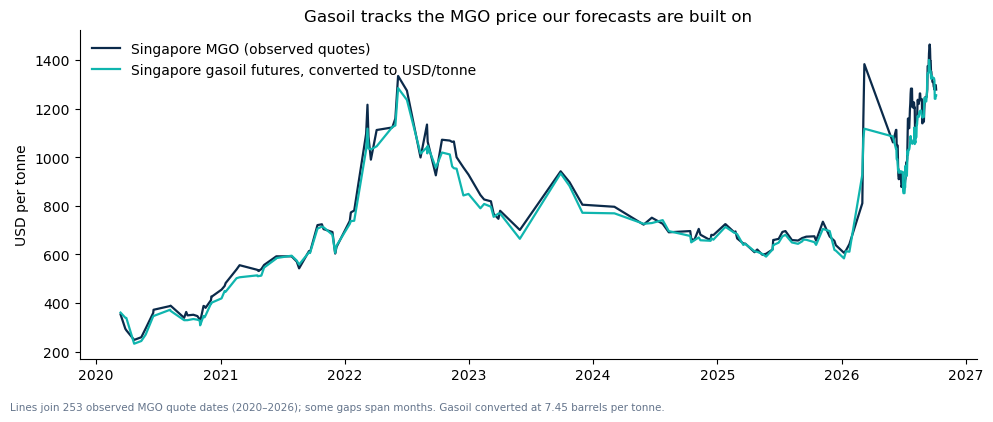

In [14]:
fig, ax = plt.subplots(figsize=(10, 4.2))
ax.plot(matched.mgo_date, matched.mgo_usd_per_t, lw=1.6, color="#0B2A4A", label="Singapore MGO (observed quotes)")
ax.plot(matched.mgo_date, matched.gasoil_usd_per_t, lw=1.6, color="#0FB5AE",
        label="Singapore gasoil futures, converted to USD/tonne")
ax.set_ylabel("USD per tonne")
ax.set_title("Gasoil tracks the MGO price our forecasts are built on")
ax.legend(frameon=False, loc="upper left")
fig.text(0.01, 0.01, f"Lines join {len(matched)} observed MGO quote dates (2020–2026); some gaps span months. "
         f"Gasoil converted at {BBL_PER_TONNE} barrels per tonne.", fontsize=7.5, color="#64748B")
for side in ("top", "right"):
    ax.spines[side].set_visible(False)
fig.tight_layout(rect=(0, 0.04, 1, 1))
fig.savefig(OUT / "model_trust_chart.png", dpi=160)
print("Saved", (OUT / "model_trust_chart.png").relative_to(REPO))
plt.show()

## 6. Conclusions

*(Numbers below come from this notebook's outputs above.)*

**Short answer: gasoil is a reasonable proxy for MGO.**

**What the data shows**
- **Same price level once units match.** Converted at 7.45 barrels/tonne (≈ 0.844 kg/L), gasoil sits right next to
  MGO: a median gap of only **$21.6/t**, and price levels correlate at **0.986**.
- **They move together.** Across all 252 consecutive MGO quotes, MGO % changes correlate with gasoil % changes at
  **r = 0.80**. MGO moves about **85% as much as gasoil** (slope **0.83**, 95% CI 0.75–0.90; **0.87** without the
  March 2026 shock).
- **Gasoil explains MGO moves.** Moving MGO by gasoil's actual % change cuts the error versus "no change" by
  **28%** (MAE **$31.05 → $22.50/t**), and by **32%** using gasoil up to the previous day (**$21.02/t**).
- **The relationship holds across market conditions**: slopes of 0.81 (2020–21), 1.06 (2022) and 0.85 (2023–25),
  with correlations of 0.86–0.92, and it stays clearly positive through volatile 2026 (slope 0.64, r = 0.59).

**Basis conversion rule**
- To move an MGO price with gasoil: `MGO_est = MGO_last × (1 + gasoil % change since the last MGO quote)`,
  measuring gasoil **up to the previous trading day**.
- To convert a gasoil level to an MGO level: `MGO ≈ 7.45 × gasoil (USD/bbl) + basis`, with a typical basis of
  ~$20/t.
- Equal percentage movement is **well supported** as a simple rule; MGO tends to move slightly less than gasoil
  (~85%), so a damped transfer (~0.85×) is a possible refinement to validate later.

**Things to keep in mind**
- **Strongest over days to weeks.** Day-to-day MGO quotes are noisier (34% of short-interval quotes don't change),
  so the link is clearest over multi-day moves. MGO lines up best with the **previous day's** gasoil (r = 0.59 vs
  0.40 same day for quotes ≤ 7 days apart).
- **The basis can widen during market shocks**, e.g. March 2026 (MGO jumped 70% in six days vs gasoil's ~20%) and
  July–August 2026 (gap $165–222/t), before narrowing again.
- **Based on actual moves.** These comparisons use observed gasoil, so they show how well gasoil represents MGO,
  separately from how well gasoil itself can be forecast.
- **Data notes.** 7.45 barrels per tonne is the conversion ICE Futures (Intercontinental Exchange) uses for the Platts Singapore
  gasoil price in its contract specifications (see section 1), not a figure derived from our data; MGO's exact grade and quote publication
  times aren't recorded; 126 of the 253 quotes are from 2026. Gasoil is used as a proxy and isn't labelled as an
  observed MGO price.